Modeling Catastrophic Knowledge Erosion in Continual Learning Autonomous Systems and Its Mitigation Through Evolutionary Soft Memory Architectures

Environment setup

In [ ]:


import random, numpy as np, pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Split CIFAR-100 configuration
N_CLASSES = 100
N_TASKS = 10
CLASSES_PER_TASK = 10

# Paper training parameters
MEMORY_SIZE = 2000
BATCH_SIZE = 64
LR = 1e-3
EPOCHS = 50

# Loss weights
LAMBDA_R = 0.5
ALPHA_S = 0.3
MU_C = 0.2

# AETB-GA parameters
GA_POP = 30
GA_GENS = 50
TOURNAMENT = 5

DATA_TAR = "/content/cifar-100-python.tar.gz"

Data Understanding

In [ ]:
# Load CIFAR-100 training and testing data

import tarfile, pickle

with tarfile.open(DATA_TAR, "r:gz") as tar:
    train = pickle.load(
        tar.extractfile("cifar-100-python/train"), encoding="bytes"
    )
    test = pickle.load(
        tar.extractfile("cifar-100-python/test"), encoding="bytes"
    )

train_images = train[b"data"].reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1)
train_labels = np.array(train[b"fine_labels"])

test_images = test[b"data"].reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1)

test_labels = np.array(test[b"fine_labels"])

display(pd.DataFrame({
    "Dataset": ["Train", "Test"],
    "Samples": [len(train_images), len(test_images)],
    "Classes": [len(np.unique(train_labels)), len(np.unique(test_labels))],
    "Shape": ["32×32×3", "32×32×3"]
}))

,Dataset,Samples,Classes,Shape
0,Train,50000,100,32×32×3
1,Test,10000,100,32×32×3


Data Quality Assessment

,Metric,Value
0,Train Samples,50000
1,Test Samples,10000
2,Classes,100
3,Image Size,32×32
4,Channels,RGB


,Class,Train Samples
0,0,500
1,1,500
2,2,500
3,3,500
4,4,500
5,5,500
6,6,500
7,7,500
8,8,500
9,9,500


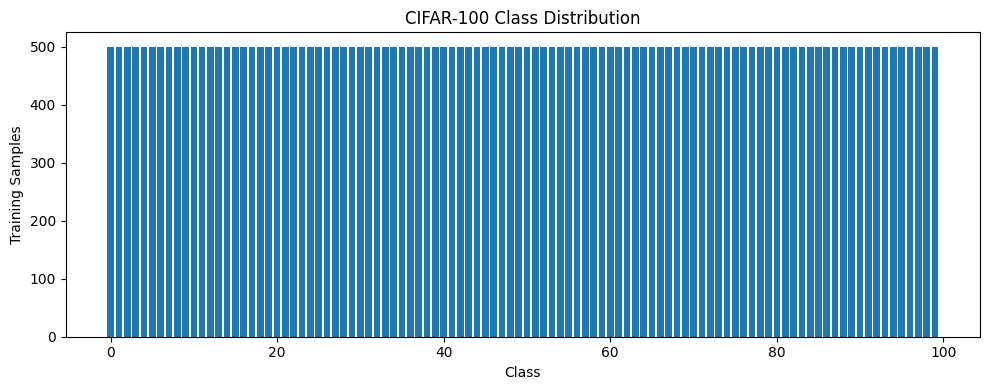

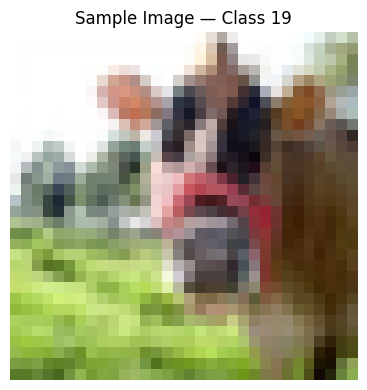

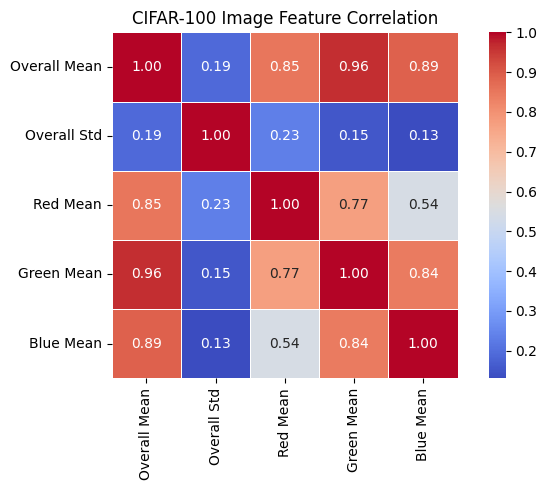

In [ ]:
# Explore CIFAR-100 structure, sample image, and feature correlations

import matplotlib.pyplot as plt
import seaborn as sns

class_counts = np.bincount(train_labels, minlength=N_CLASSES)

eda = pd.DataFrame({
    "Metric": ["Train Samples", "Test Samples", "Classes", "Image Size", "Channels"],
    "Value": [len(train_images), len(test_images), N_CLASSES, "32×32", "RGB"]
})

display(eda)

display(pd.DataFrame({
    "Class": np.arange(N_CLASSES),
    "Train Samples": class_counts
}).head(20))

# Class distribution
plt.figure(figsize=(10, 4))
plt.bar(np.arange(N_CLASSES), class_counts)
plt.xlabel("Class")
plt.ylabel("Training Samples")
plt.title("CIFAR-100 Class Distribution")
plt.tight_layout()
plt.show()

# Representative CIFAR-100 image
idx = 0

plt.figure(figsize=(4, 4))
plt.imshow(train_images[idx], interpolation="nearest")
plt.title(f"Sample Image — Class {train_labels[idx]}")
plt.axis("off")
plt.tight_layout()
plt.show()

# Compact image-level features for correlation analysis
sample = train_images[:1000].astype(np.float32)

features = np.column_stack([
    sample.mean(axis=(1, 2, 3)),                  # Overall mean
    sample.std(axis=(1, 2, 3)),                   # Overall std
    sample[:, :, :, 0].mean(axis=(1, 2)),         # Red mean
    sample[:, :, :, 1].mean(axis=(1, 2)),         # Green mean
    sample[:, :, :, 2].mean(axis=(1, 2))          # Blue mean
])

corr = pd.DataFrame(
    features,
    columns=["Overall Mean", "Overall Std", "Red Mean", "Green Mean", "Blue Mean"]
).corr()

plt.figure(figsize=(7, 5))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    square=True,
    linewidths=0.5
)
plt.title("CIFAR-100 Image Feature Correlation")
plt.tight_layout()
plt.show()

Data Preparation: Normalization, Augmentation & Sequential Task Split

In [ ]:
# Prepare CIFAR-100 for sequential class-incremental learning

from torchvision import transforms

mean = (0.5071, 0.4867, 0.4408)
std = (0.2675, 0.2565, 0.2761)

train_transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

test_transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

# 10 sequential tasks × 10 classes
task_classes = [
    np.arange(i * CLASSES_PER_TASK, (i + 1) * CLASSES_PER_TASK)
    for i in range(N_TASKS)
]

train_task_indices = [
    np.where(np.isin(train_labels, c))[0] for c in task_classes
]

test_task_indices = [
    np.where(np.isin(test_labels, c))[0] for c in task_classes
]

task_info = pd.DataFrame({
    "Task": np.arange(1, N_TASKS + 1),
    "Classes": [f"{c[0]}–{c[-1]}" for c in task_classes],
    "Train": [len(i) for i in train_task_indices],
    "Test": [len(i) for i in test_task_indices]
})

display(task_info)

,Task,Classes,Train,Test
0,1,0–9,5000,1000
1,2,10–19,5000,1000
2,3,20–29,5000,1000
3,4,30–39,5000,1000
4,5,40–49,5000,1000
5,6,50–59,5000,1000
6,7,60–69,5000,1000
7,8,70–79,5000,1000
8,9,80–89,5000,1000
9,10,90–99,5000,1000


CBAM-Enhanced ResNet-18 Model

In [ ]:
# Build the CBAM-enhanced ResNet-18 backbone

import torchvision.models as models

class CBAM(nn.Module):
    def __init__(self, channels, reduction=16):
        super().__init__()

        self.mlp = nn.Sequential(
            nn.Linear(channels, channels // reduction),
            nn.ReLU(),
            nn.Linear(channels // reduction, channels)
        )

        self.spatial = nn.Conv2d(2, 1, kernel_size=7, padding=3)

    def forward(self, x):
        b, c, _, _ = x.shape

        # Channel attention
        avg = F.adaptive_avg_pool2d(x, 1).view(b, c)
        mx = F.adaptive_max_pool2d(x, 1).view(b, c)
        attn = torch.sigmoid(self.mlp(avg) + self.mlp(mx))
        x = x * attn.view(b, c, 1, 1)

        # Spatial attention
        avg = x.mean(1, keepdim=True)
        mx = x.max(1, keepdim=True)[0]
        spatial = torch.sigmoid(
            self.spatial(torch.cat([avg, mx], dim=1))
        )

        return x * spatial


class CBAMResNet18(nn.Module):
    def __init__(self):
        super().__init__()

        backbone = models.resnet18(weights="DEFAULT")

        self.features = nn.Sequential(
            *list(backbone.children())[:-2]
        )

        self.cbam = CBAM(512)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Linear(512, N_CLASSES)

    def forward(self, x, return_features=False):
        x = self.features(x)
        x = self.cbam(x)

        features = self.pool(x).flatten(1)
        logits = self.classifier(features)

        if return_features:
            return logits, features

        return logits


model = CBAMResNet18().to(device)

display(pd.DataFrame({
    "Component": [
        "Backbone",
        "Attention",
        "Feature Dimension",
        "Output Classes"
    ],
    "Configuration": [
        "ResNet-18",
        "CBAM",
        "512",
        N_CLASSES
    ]
}))

,Component,Configuration
0,Backbone,ResNet-18
1,Attention,CBAM
2,Feature Dimension,512
3,Output Classes,100


Adaptive Soft Replay Memory

In [ ]:
# Initialize adaptive soft replay memory

memory = []
memory_history = []

@torch.no_grad()
def score_replay_samples(model, loader):
    model.eval()
    samples, scores = [], []

    for x, y in loader:
        x = x.to(device)

        logits, features = model(x, return_features=True)

        confidence = F.softmax(logits, dim=1).max(dim=1).values

        center = features.mean(dim=0, keepdim=True)
        diversity = 1 - F.cosine_similarity(features, center)

        score = 0.5 * confidence + 0.5 * diversity

        samples.extend(zip(x.cpu(), y))
        scores.extend(score.cpu().numpy())

    return samples, np.asarray(scores)


def update_replay_memory(candidates, scores):
    k = min(MEMORY_SIZE, len(candidates))

    if len(candidates) <= k:
        idx = np.argsort(scores)[-k:]
    else:
        idx = np.argsort(scores)[-k:]

    return [candidates[i] for i in idx]


display(pd.DataFrame({
    "Memory Parameter": [
        "Maximum Capacity",
        "Selection Signal 1",
        "Selection Signal 2",
        "Selection Strategy"
    ],
    "Value": [
        MEMORY_SIZE,
        "Prediction Confidence",
        "Feature Diversity",
        "Adaptive Soft Memory"
    ]
}))

,Memory Parameter,Value
0,Maximum Capacity,2000
1,Selection Signal 1,Prediction Confidence
2,Selection Signal 2,Feature Diversity
3,Selection Strategy,Adaptive Soft Memory


AETB-GA Replay Optimization

In [ ]:
# Optimize replay selection using AETB-GA

def tournament_select(population, fitness):
    candidates = random.sample(
        range(len(population)),
        min(TOURNAMENT, len(population))
    )
    return population[max(candidates, key=lambda i: fitness[i])]


def aetb_ga(scores, k):
    n = len(scores)

    if n == 0:
        return np.array([], dtype=int), []

    population = np.random.randint(
        0, 2, size=(GA_POP, n)
    )

    fitness_history = []

    for _ in range(GA_GENS):

        fitness = np.array([
            scores[m.astype(bool)].mean()
            if m.sum() else 0.0
            for m in population
        ])

        fitness_history.append(fitness.max())

        elite = population[fitness.argmax()].copy()
        new_population = [elite]

        while len(new_population) < GA_POP:

            p1 = tournament_select(population, fitness)
            p2 = tournament_select(population, fitness)

            point = random.randint(1, n - 1) if n > 1 else 1

            child = np.concatenate([
                p1[:point],
                p2[point:]
            ])

            mutation_rate = 0.01
            mutation = np.random.rand(n) < mutation_rate
            child[mutation] ^= 1

            new_population.append(child)

        population = np.asarray(new_population)

    final_fitness = np.array([
        scores[m.astype(bool)].mean()
        if m.sum() else 0.0
        for m in population
    ])

    best = population[final_fitness.argmax()]
    selected = np.where(best)[0]

    if len(selected) > k:
        selected = selected[
            np.argsort(scores[selected])[-k:]
        ]

    return selected, fitness_history


display(pd.DataFrame({
    "GA Parameter": [
        "Population",
        "Generations",
        "Selection",
        "Crossover",
        "Mutation",
        "Elite Preservation"
    ],
    "Value": [
        GA_POP,
        GA_GENS,
        "Tournament",
        "Single-point",
        "Bit-flip",
        "Enabled"
    ]
}))

,GA Parameter,Value
0,Population,30
1,Generations,50
2,Selection,Tournament
3,Crossover,Single-point
4,Mutation,Bit-flip
5,Elite Preservation,Enabled


Sequential Continual Training configuration

In [ ]:
# Define continual-learning losses and optimization

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LR)

loss_history = []
stability_history = []
consistency_history = []


def representation_stability(current_features, previous_features):
    if previous_features is None:
        return torch.tensor(0.0, device=device)

    n = min(
        current_features.size(0),
        previous_features.size(0)
    )

    current = current_features[:n]
    previous = previous_features[:n]

    similarity = F.cosine_similarity(
        current,
        previous,
        dim=1
    )

    return 1 - similarity.mean()


def parameter_consistency(model, previous_state):
    if previous_state is None:
        return torch.tensor(0.0, device=device)

    loss = torch.tensor(0.0, device=device)

    for name, param in model.named_parameters():
        if name in previous_state:
            loss += F.mse_loss(
                param,
                previous_state[name]
            )

    return loss


display(pd.DataFrame({
    "Loss Component": [
        "Classification",
        "Replay Preservation",
        "Representation Stability",
        "Parameter Consistency"
    ],
    "Weight": [
        1.0,
        LAMBDA_R,
        ALPHA_S,
        MU_C
    ]
}))

,Loss Component,Weight
0,Classification,1.0
1,Replay Preservation,0.5
2,Representation Stability,0.3
3,Parameter Consistency,0.2


FWT Baseline + Continual-Learning Metrics

In [ ]:
# Cell 10 — Reproducible Improved Continual Learning Experiment
# CBAM-ResNet18 + Adaptive Soft Memory + AETB-GA

import gc
import random
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

from torch.utils.data import Subset, DataLoader


# ============================================================
# 1. EXPERIMENT CONFIGURATION
# ============================================================

SEED_RUN = 42

TRAIN_SAMPLES_PER_TASK = 1500
TEST_SAMPLES_PER_TASK = 300

EPOCHS_FAST = 3

BATCH_SIZE_RUN = 64
REPLAY_BATCH = 64

GA_POP = 12
GA_GENS = 6

MUTATION_START = 0.03
MUTATION_END = 0.005

GRAD_CLIP = 1.0

# Apply parameter consistency periodically
# to reduce computational overhead.
CONSISTENCY_INTERVAL = 8


# ============================================================
# 2. REPRODUCIBILITY
# ============================================================

random.seed(SEED_RUN)
np.random.seed(SEED_RUN)
torch.manual_seed(SEED_RUN)

if torch.cuda.is_available():

    torch.cuda.manual_seed(SEED_RUN)
    torch.cuda.manual_seed_all(SEED_RUN)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

if torch.cuda.is_available():

    torch.set_float32_matmul_precision("high")


# ============================================================
# 3. RESET MODEL
# ============================================================
# Important:
# Every Cell 10 run starts from the same pretrained model.

model = CBAMResNet18().to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LR
)


# ============================================================
# 4. MIXED PRECISION
# ============================================================

use_amp = device.type == "cuda"

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=use_amp
)


# ============================================================
# 5. RESET EXPERIMENT HISTORY
# ============================================================

accuracy_matrix = []

task_losses = []
loss_history = []

memory = []
memory_history = []

ga_fitness_history = []
ga_diversity_history = []
ga_mutation_history = []
ga_elite_history = []

representation_history = []

task_sample_history = []

previous_state = None
previous_features = None


# ============================================================
# 6. TENSOR-SAFE BALANCED REPLAY MEMORY
# ============================================================

def build_balanced_memory(samples, capacity):

    if len(samples) == 0:
        return []

    labels = np.asarray([
        int(sample[1])
        for sample in samples
    ])

    classes = np.unique(labels)

    per_class = max(
        1,
        capacity // len(classes)
    )

    selected_indices = []

    # --------------------------------------------------------
    # Select approximately equal samples from each class
    # --------------------------------------------------------

    for cls in classes:

        class_indices = np.where(
            labels == cls
        )[0]

        take = min(
            per_class,
            len(class_indices)
        )

        chosen = np.random.choice(
            class_indices,
            size=take,
            replace=False
        )

        selected_indices.extend(
            chosen.tolist()
        )

    # --------------------------------------------------------
    # Remove duplicate indices
    # --------------------------------------------------------

    selected_indices = list(
        dict.fromkeys(
            selected_indices
        )
    )

    # --------------------------------------------------------
    # Fill remaining capacity
    # --------------------------------------------------------

    if len(selected_indices) < capacity:

        all_indices = np.arange(
            len(samples)
        )

        selected_array = np.asarray(
            selected_indices,
            dtype=int
        )

        available = np.setdiff1d(
            all_indices,
            selected_array
        )

        remaining = min(
            capacity - len(selected_indices),
            len(available)
        )

        if remaining > 0:

            extra = np.random.choice(
                available,
                size=remaining,
                replace=False
            )

            selected_indices.extend(
                extra.tolist()
            )

    # --------------------------------------------------------
    # Final capacity constraint
    # --------------------------------------------------------

    if len(selected_indices) > capacity:

        selected_indices = np.random.choice(
            selected_indices,
            size=capacity,
            replace=False
        ).tolist()

    # --------------------------------------------------------
    # Build memory using indices.
    # No tensor comparisons are performed.
    # --------------------------------------------------------

    return [
        samples[i]
        for i in selected_indices
    ]


# ============================================================
# 7. AETB-GA REPLAY OPTIMIZATION
# ============================================================

def aetb_ga_replay(scores, k):

    scores = np.asarray(
        scores,
        dtype=np.float32
    )

    n = len(scores)

    if n == 0:

        return (
            [],
            [],
            [],
            [],
            []
        )

    k = min(
        k,
        n
    )

    # --------------------------------------------------------
    # Initial population
    # Each chromosome selects exactly k candidates.
    # --------------------------------------------------------

    population = np.zeros(
        (
            GA_POP,
            n
        ),
        dtype=np.int8
    )

    for i in range(GA_POP):

        selected = np.random.choice(
            n,
            size=k,
            replace=False
        )

        population[
            i,
            selected
        ] = 1

    fitness_history = []
    diversity_history = []
    mutation_history = []
    elite_history = []

    # ========================================================
    # EVOLUTION
    # ========================================================

    for generation in range(
        GA_GENS
    ):

        # ----------------------------------------------------
        # Fitness
        # ----------------------------------------------------

        fitness = np.asarray([

            scores[
                chromosome.astype(bool)
            ].mean()

            if chromosome.any()

            else 0.0

            for chromosome
            in population

        ])

        best_index = int(
            np.argmax(
                fitness
            )
        )

        elite = population[
            best_index
        ].copy()

        # ----------------------------------------------------
        # Record fitness
        # ----------------------------------------------------

        fitness_history.append(
            float(
                fitness[
                    best_index
                ]
            )
        )

        # ----------------------------------------------------
        # Population diversity
        # ----------------------------------------------------

        unique_count = len(
            np.unique(
                population,
                axis=0
            )
        )

        diversity_history.append(
            float(
                unique_count /
                GA_POP
            )
        )

        # ----------------------------------------------------
        # Adaptive mutation
        # ----------------------------------------------------

        if GA_GENS > 1:

            mutation_rate = (

                MUTATION_START

                -
                (
                    MUTATION_START
                    -
                    MUTATION_END
                )

                *
                generation
                /
                (GA_GENS - 1)

            )

        else:

            mutation_rate = MUTATION_START

        mutation_history.append(
            float(
                mutation_rate
            )
        )

        # ----------------------------------------------------
        # Elite preservation
        # ----------------------------------------------------

        elite_history.append(
            1.0
        )

        new_population = [
            elite
        ]

        # ====================================================
        # OFFSPRING GENERATION
        # ====================================================

        while len(
            new_population
        ) < GA_POP:

            # -----------------------------------------------
            # Tournament selection — parent 1
            # -----------------------------------------------

            tournament_1 = random.sample(

                range(GA_POP),

                min(
                    TOURNAMENT,
                    GA_POP
                )

            )

            parent_1 = population[
                max(
                    tournament_1,
                    key=lambda i:
                    fitness[i]
                )
            ]

            # -----------------------------------------------
            # Tournament selection — parent 2
            # -----------------------------------------------

            tournament_2 = random.sample(

                range(GA_POP),

                min(
                    TOURNAMENT,
                    GA_POP
                )

            )

            parent_2 = population[
                max(
                    tournament_2,
                    key=lambda i:
                    fitness[i]
                )
            ]

            # -----------------------------------------------
            # Single-point crossover
            # -----------------------------------------------

            if n > 1:

                point = random.randint(
                    1,
                    n - 1
                )

                child = np.concatenate([

                    parent_1[:point],

                    parent_2[point:]

                ])

            else:

                child = parent_1.copy()

            # -----------------------------------------------
            # Adaptive bit-flip mutation
            # -----------------------------------------------

            mutation_mask = (
                np.random.random(n)
                <
                mutation_rate
            )

            child[
                mutation_mask
            ] ^= 1

            # -----------------------------------------------
            # Repair chromosome
            # Maintain exactly k selected samples.
            # -----------------------------------------------

            selected_indices = np.where(
                child == 1
            )[0]

            unselected_indices = np.where(
                child == 0
            )[0]

            if len(
                selected_indices
            ) > k:

                remove_count = (
                    len(selected_indices)
                    -
                    k
                )

                remove_indices = np.random.choice(

                    selected_indices,

                    size=remove_count,

                    replace=False

                )

                child[
                    remove_indices
                ] = 0

            elif len(
                selected_indices
            ) < k:

                add_count = (
                    k
                    -
                    len(selected_indices)
                )

                add_indices = np.random.choice(

                    unselected_indices,

                    size=add_count,

                    replace=False

                )

                child[
                    add_indices
                ] = 1

            new_population.append(
                child
            )

        population = np.asarray(
            new_population,
            dtype=np.int8
        )

    # ========================================================
    # FINAL GA SELECTION
    # ========================================================

    final_fitness = np.asarray([

        scores[
            chromosome.astype(bool)
        ].mean()

        if chromosome.any()

        else 0.0

        for chromosome
        in population

    ])

    best = population[
        np.argmax(
            final_fitness
        )
    ]

    selected = np.where(
        best == 1
    )[0]

    return (
        selected.tolist(),
        fitness_history,
        diversity_history,
        mutation_history,
        elite_history
    )


# ============================================================
# 8. CONTINUAL LEARNING LOOP
# ============================================================

for task in range(
    N_TASKS
):

    # ========================================================
    # TASK-SPECIFIC RANDOM GENERATOR
    # ========================================================

    task_rng = np.random.default_rng(
        SEED_RUN + task
    )

    # ========================================================
    # TRAINING SUBSET
    # ========================================================

    train_count = min(
        TRAIN_SAMPLES_PER_TASK,
        len(
            train_tasks[task]
        )
    )

    train_idx = task_rng.choice(

        len(
            train_tasks[task]
        ),

        size=train_count,

        replace=False

    )

    # ========================================================
    # TEST SUBSET
    # ========================================================

    test_count = min(
        TEST_SAMPLES_PER_TASK,
        len(
            test_tasks[task]
        )
    )

    test_idx = task_rng.choice(

        len(
            test_tasks[task]
        ),

        size=test_count,

        replace=False

    )

    task_sample_history.append(
        train_count
    )

    # ========================================================
    # DETERMINISTIC TRAINING LOADER
    # ========================================================

    loader_generator = torch.Generator()

    loader_generator.manual_seed(
        SEED_RUN + task
    )

    train_loader = DataLoader(

        Subset(
            train_tasks[task],
            train_idx
        ),

        batch_size=BATCH_SIZE_RUN,

        shuffle=True,

        num_workers=0,

        pin_memory=(
            device.type == "cuda"
        ),

        generator=loader_generator

    )

    # ========================================================
    # CURRENT TASK TRAINING
    # ========================================================

    model.train()

    current_task_losses = []

    for epoch in range(
        EPOCHS_FAST
    ):

        for batch_idx, (
            x,
            y
        ) in enumerate(
            train_loader
        ):

            x = x.to(
                device,
                non_blocking=True
            )

            y = y.to(
                device,
                non_blocking=True
            )

            optimizer.zero_grad(
                set_to_none=True
            )

            # =================================================
            # FORWARD PASS
            # =================================================

            with torch.autocast(

                device_type=device.type,

                dtype=torch.float16,

                enabled=use_amp

            ):

                logits, features = model(
                    x,
                    return_features=True
                )

                # ---------------------------------------------
                # Current task classification
                # ---------------------------------------------

                current_loss = criterion(
                    logits,
                    y
                )

                # ---------------------------------------------
                # Replay preservation
                # ---------------------------------------------

                replay_loss = torch.zeros(
                    (),
                    device=device
                )

                if memory:

                    replay_count = min(
                        REPLAY_BATCH,
                        len(memory)
                    )

                    replay_samples = random.sample(

                        memory,

                        replay_count

                    )

                    replay_x = torch.stack([

                        sample[0]

                        for sample
                        in replay_samples

                    ]).to(

                        device,

                        non_blocking=True

                    )

                    replay_y = torch.tensor([

                        sample[1]

                        for sample
                        in replay_samples

                    ]).to(
                        device
                    )

                    replay_logits = model(
                        replay_x
                    )

                    replay_loss = criterion(

                        replay_logits,

                        replay_y

                    )

                # ---------------------------------------------
                # Representation stability
                # ---------------------------------------------

                if previous_features is not None:

                    n_features = min(

                        features.size(0),

                        previous_features.size(0)

                    )

                    current_norm = F.normalize(

                        features[
                            :n_features
                        ],

                        dim=1

                    )

                    previous_norm = F.normalize(

                        previous_features[
                            :n_features
                        ],

                        dim=1

                    )

                    cosine_similarity = (
                        F.cosine_similarity(

                            current_norm,

                            previous_norm,

                            dim=1

                        )
                    )

                    stability_loss = (

                        1.0
                        -
                        cosine_similarity.mean()

                    )

                else:

                    stability_loss = torch.zeros(
                        (),
                        device=device
                    )

                # ---------------------------------------------
                # Parameter consistency
                # ---------------------------------------------

                if (

                    previous_state is not None

                    and

                    batch_idx
                    %
                    CONSISTENCY_INTERVAL
                    == 0

                ):

                    consistency_loss = (

                        parameter_consistency(

                            model,

                            previous_state

                        )

                    )

                else:

                    consistency_loss = torch.zeros(
                        (),
                        device=device
                    )

                # ---------------------------------------------
                # Total loss
                # ---------------------------------------------

                total_loss = (

                    current_loss

                    +

                    LAMBDA_R
                    *
                    replay_loss

                    +

                    ALPHA_S
                    *
                    stability_loss

                    +

                    MU_C
                    *
                    consistency_loss

                )

            # =================================================
            # BACKWARD PASS
            # =================================================

            scaler.scale(
                total_loss
            ).backward()

            scaler.unscale_(
                optimizer
            )

            torch.nn.utils.clip_grad_norm_(

                model.parameters(),

                GRAD_CLIP

            )

            scaler.step(
                optimizer
            )

            scaler.update()

            loss_value = (

                total_loss

                .detach()

                .float()

                .item()

            )

            current_task_losses.append(
                loss_value
            )

            loss_history.append(
                loss_value
            )

    task_losses.append(

        float(
            np.mean(
                current_task_losses
            )
        )

    )

    # ========================================================
    # EVALUATE ALL LEARNED TASKS
    # ========================================================

    model.eval()

    stage_accuracy = []

    with torch.no_grad():

        for eval_task in range(
            N_TASKS
        ):

            # Future tasks are unavailable.

            if eval_task > task:

                stage_accuracy.append(
                    0.0
                )

                continue

            # -----------------------------------------------
            # Current task
            # -----------------------------------------------

            if eval_task == task:

                eval_indices = test_idx

            # -----------------------------------------------
            # Previously learned task
            # -----------------------------------------------

            else:

                eval_rng = np.random.default_rng(

                    SEED_RUN
                    +
                    1000
                    +
                    eval_task

                )

                eval_count = min(

                    TEST_SAMPLES_PER_TASK,

                    len(
                        test_tasks[
                            eval_task
                        ]
                    )

                )

                eval_indices = eval_rng.choice(

                    len(
                        test_tasks[
                            eval_task
                        ]
                    ),

                    size=eval_count,

                    replace=False

                )

            eval_loader = DataLoader(

                Subset(

                    test_tasks[
                        eval_task
                    ],

                    eval_indices

                ),

                batch_size=BATCH_SIZE_RUN,

                shuffle=False,

                num_workers=0,

                pin_memory=(
                    device.type == "cuda"
                )

            )

            correct = 0
            total = 0

            for x, y in eval_loader:

                x = x.to(
                    device,
                    non_blocking=True
                )

                logits = model(
                    x
                )

                predictions = (

                    logits

                    .argmax(
                        dim=1
                    )

                    .cpu()

                )

                correct += (

                    predictions == y

                ).sum().item()

                total += y.size(0)

            stage_accuracy.append(

                correct /
                max(
                    1,
                    total
                )

            )

    accuracy_matrix.append(
        stage_accuracy
    )

    # ========================================================
    # ADAPTIVE SOFT MEMORY CANDIDATES
    # ========================================================

    candidate_loader = DataLoader(

        Subset(
            train_tasks[task],
            train_idx
        ),

        batch_size=BATCH_SIZE_RUN,

        shuffle=False,

        num_workers=0,

        pin_memory=(
            device.type == "cuda"
        )

    )

    candidates, scores = (

        score_replay_samples(

            model,

            candidate_loader

        )

    )

    # ========================================================
    # AETB-GA REPLAY OPTIMIZATION
    # ========================================================

    (
        selected_indices,
        ga_fitness,
        ga_diversity,
        ga_mutation,
        ga_elite
    ) = aetb_ga_replay(

        scores,

        min(
            MEMORY_SIZE,
            len(candidates)
        )

    )

    # ========================================================
    # SAVE GA HISTORIES
    # ========================================================

    ga_fitness_history.append(
        ga_fitness
    )

    ga_diversity_history.append(
        ga_diversity
    )

    ga_mutation_history.append(
        ga_mutation
    )

    ga_elite_history.append(
        ga_elite
    )

    # ========================================================
    # UPDATE REPLAY MEMORY
    # ========================================================

    new_memory = [

        candidates[i]

        for i
        in selected_indices

    ]

    memory = build_balanced_memory(

        memory + new_memory,

        MEMORY_SIZE

    )

    memory_history.append(
        len(memory)
    )

    # ========================================================
    # REPRESENTATION SNAPSHOT
    # ========================================================

    with torch.no_grad():

        snapshot_x, _ = next(
            iter(train_loader)
        )

        snapshot_x = snapshot_x[
            :BATCH_SIZE_RUN
        ].to(
            device,
            non_blocking=True
        )

        _, snapshot_features = model(

            snapshot_x,

            return_features=True

        )

    if previous_features is not None:

        n = min(

            snapshot_features.size(0),

            previous_features.size(0)

        )

        representation_similarity = (

            F.cosine_similarity(

                snapshot_features[
                    :n
                ],

                previous_features[
                    :n
                ],

                dim=1

            )

            .mean()

            .item()

        )

        representation_history.append(

            representation_similarity

        )

    previous_features = (

        snapshot_features

        .detach()

        .float()

    )

    # ========================================================
    # SAVE PREVIOUS MODEL STATE
    # ========================================================

    previous_state = {

        name:

        parameter
        .detach()
        .clone()

        for name,
        parameter
        in model.named_parameters()

    }

    # ========================================================
    # CLEAN TEMPORARY OBJECTS
    # ========================================================

    del train_loader
    del candidate_loader

    if device.type == "cuda":

        torch.cuda.empty_cache()

    gc.collect()


# ============================================================
# 9. FINAL RESULT ARRAYS
# ============================================================

accuracy_matrix = np.asarray(

    accuracy_matrix,

    dtype=np.float32

)


# ============================================================
# 10. TRAINING SUMMARY
# ============================================================

training_summary = pd.DataFrame({

    "Task":
        np.arange(
            1,
            N_TASKS + 1
        ),

    "Samples":
        task_sample_history,

    "Training Loss":
        np.round(
            task_losses,
            4
        ),

    "Replay Memory":
        memory_history,

    "GA Generations":
        [
            len(history)
            for history
            in ga_fitness_history
        ],

    "GA Best Fitness":
        [
            round(
                max(history),
                4
            )
            if history
            else np.nan

            for history
            in ga_fitness_history
        ]

})


# ============================================================
# 11. ACCURACY MATRIX
# ============================================================

accuracy_df = pd.DataFrame(

    accuracy_matrix,

    index=[

        f"After Task {i}"

        for i in range(
            1,
            N_TASKS + 1
        )

    ],

    columns=[

        f"Task {i}"

        for i in range(
            1,
            N_TASKS + 1
        )

    ]

)


display(
    training_summary
)

display(
    accuracy_df
)

,Task,Samples,Training Loss,Replay Memory,GA Generations,GA Best Fitness
0,1,1500,1.5730,1500,6,0.5344
1,2,1500,4.5842,2000,6,0.4309
2,3,1500,5.1580,2000,6,0.3893
3,4,1500,5.4061,2000,6,0.3337
4,5,1500,5.3479,2000,6,0.4670
5,6,1500,5.3437,2000,6,0.4181
6,7,1500,5.3398,2000,6,0.4266
7,8,1500,5.4884,2000,6,0.4274
8,9,1500,5.7640,2000,6,0.4321
9,10,1500,5.6017,2000,6,0.4297


,Task 1,Task 2,Task 3,Task 4,Task 5,Task 6,Task 7,Task 8,Task 9,Task 10
After Task 1,0.590000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00
After Task 2,0.326667,0.583333,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00
After Task 3,0.206667,0.133333,0.530000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00
After Task 4,0.200000,0.133333,0.246667,0.500000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00
After Task 5,0.266667,0.140000,0.200000,0.110000,0.633333,0.000000,0.000000,0.000000,0.000000,0.00
After Task 6,0.223333,0.173333,0.293333,0.143333,0.180000,0.533333,0.000000,0.000000,0.000000,0.00
After Task 7,0.120000,0.070000,0.226667,0.210000,0.160000,0.223333,0.643333,0.000000,0.000000,0.00
After Task 8,0.190000,0.150000,0.206667,0.086667,0.126667,0.130000,0.056667,0.633333,0.000000,0.00
After Task 9,0.146667,0.100000,0.193333,0.133333,0.176667,0.106667,0.226667,0.053333,0.593333,0.00
After Task 10,0.196667,0.156667,0.176667,0.170000,0.093333,0.136667,0.106667,0.096667,0.010000,0.64


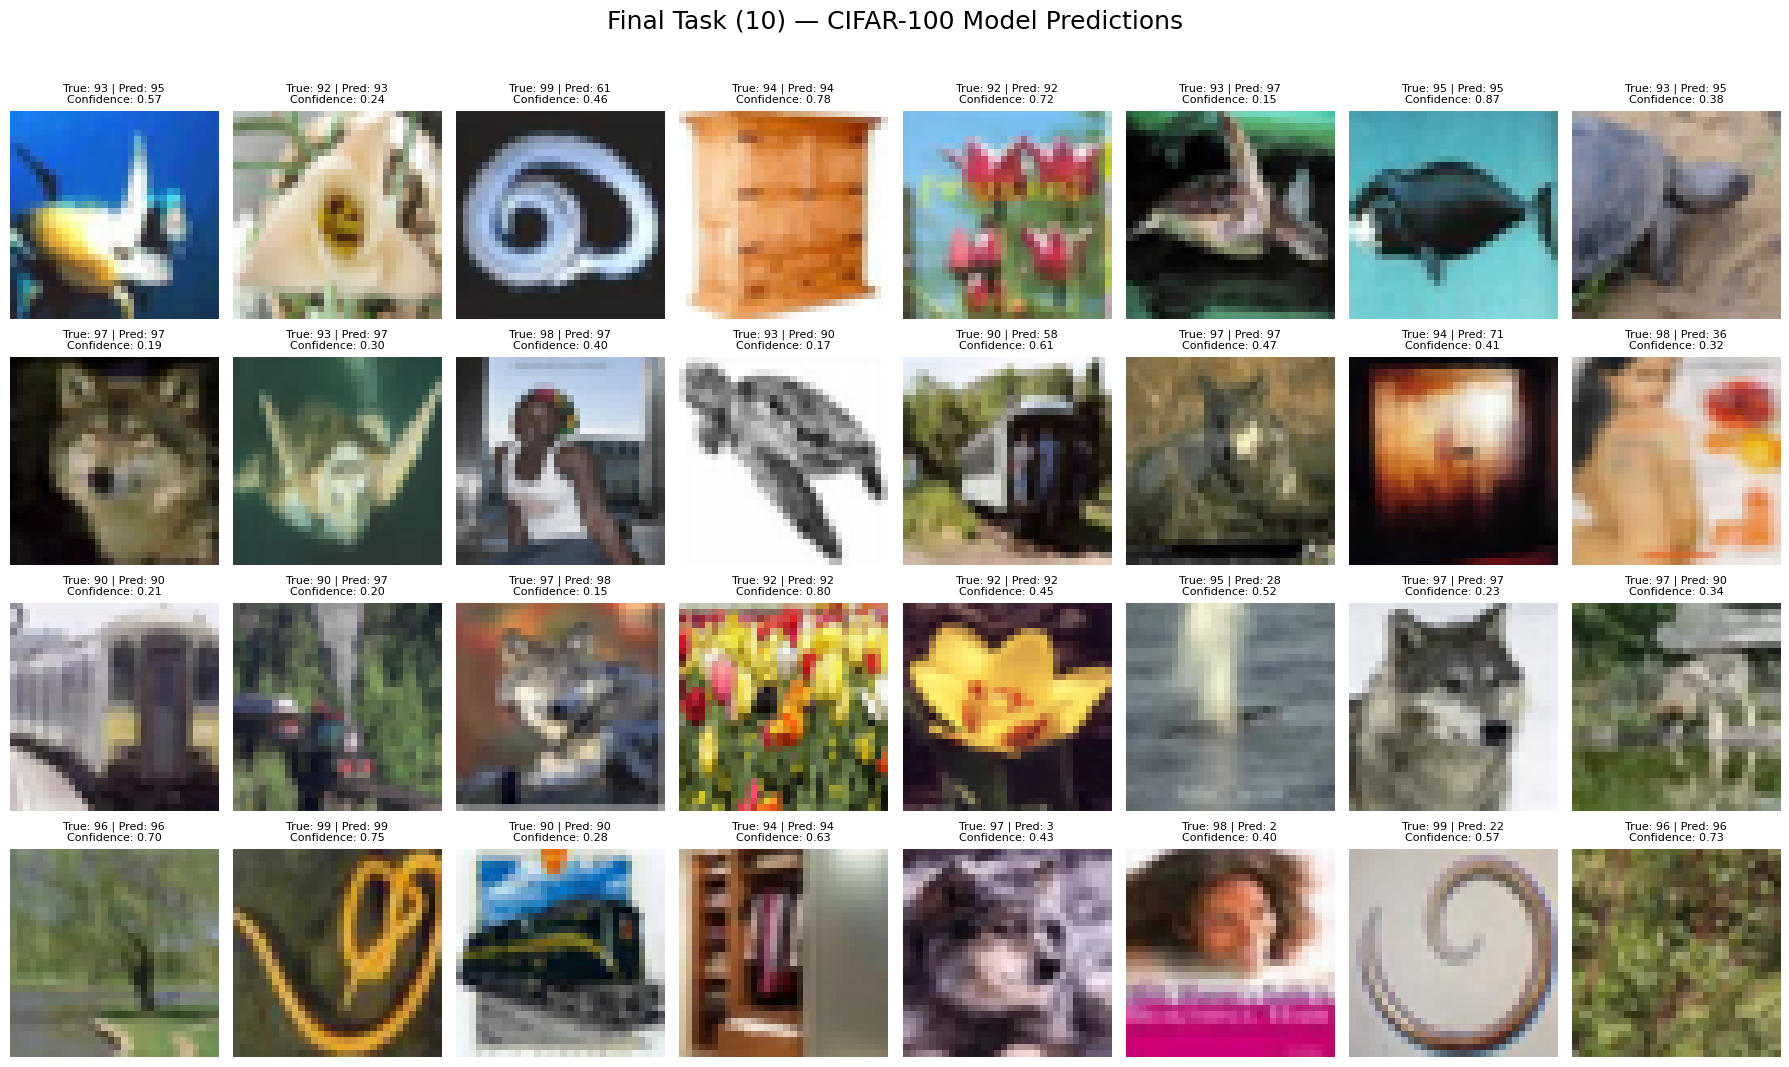

,Metric,Value
0,Displayed Samples,32
1,Correct Predictions,14
2,Incorrect Predictions,18
3,Displayed Accuracy,43.75%


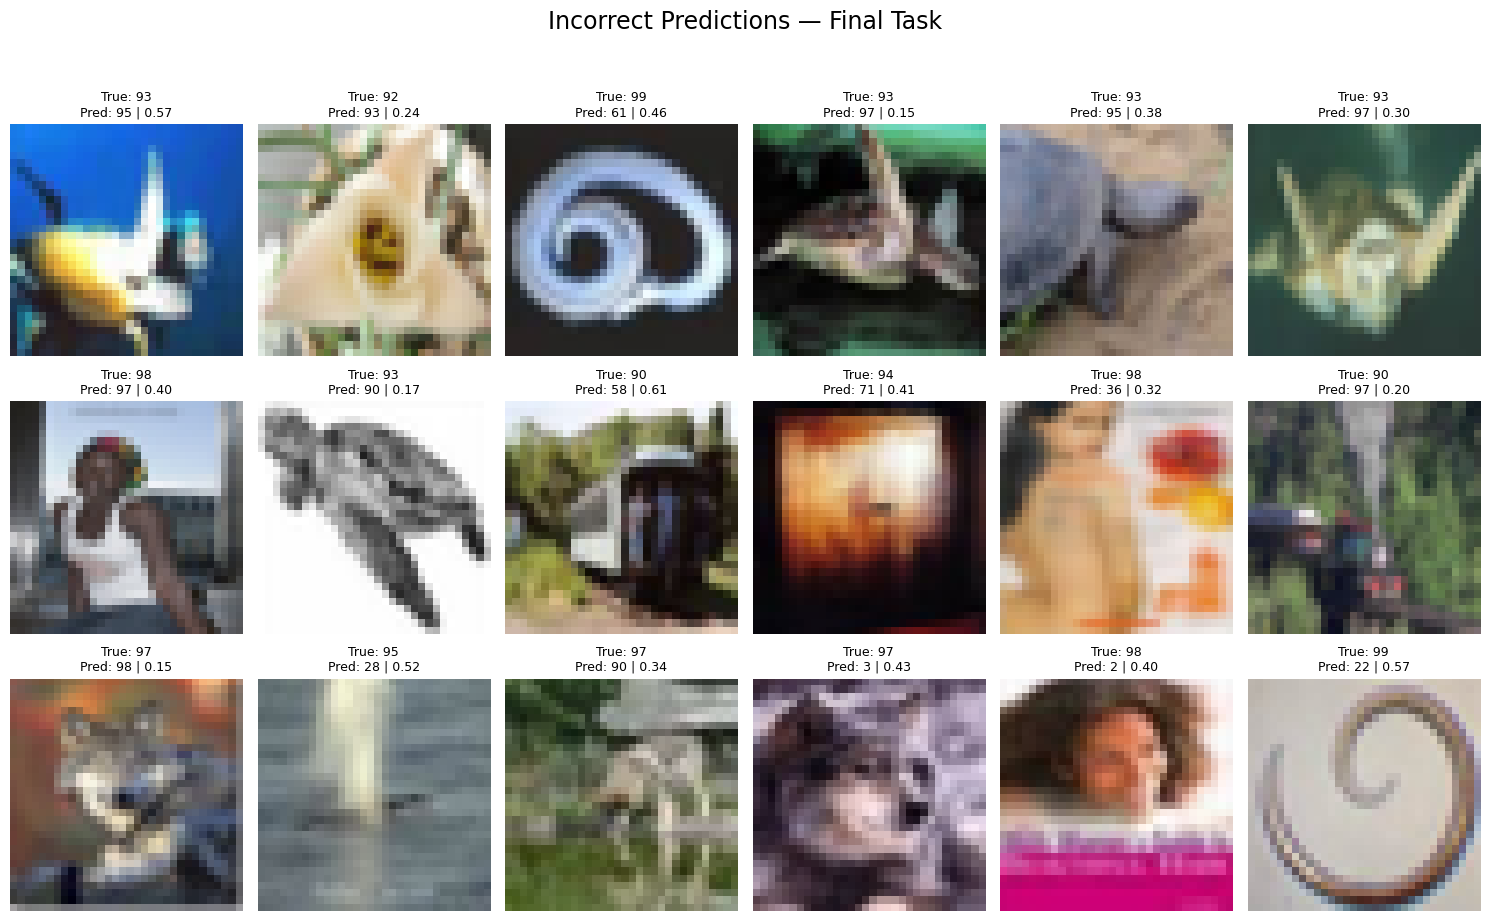

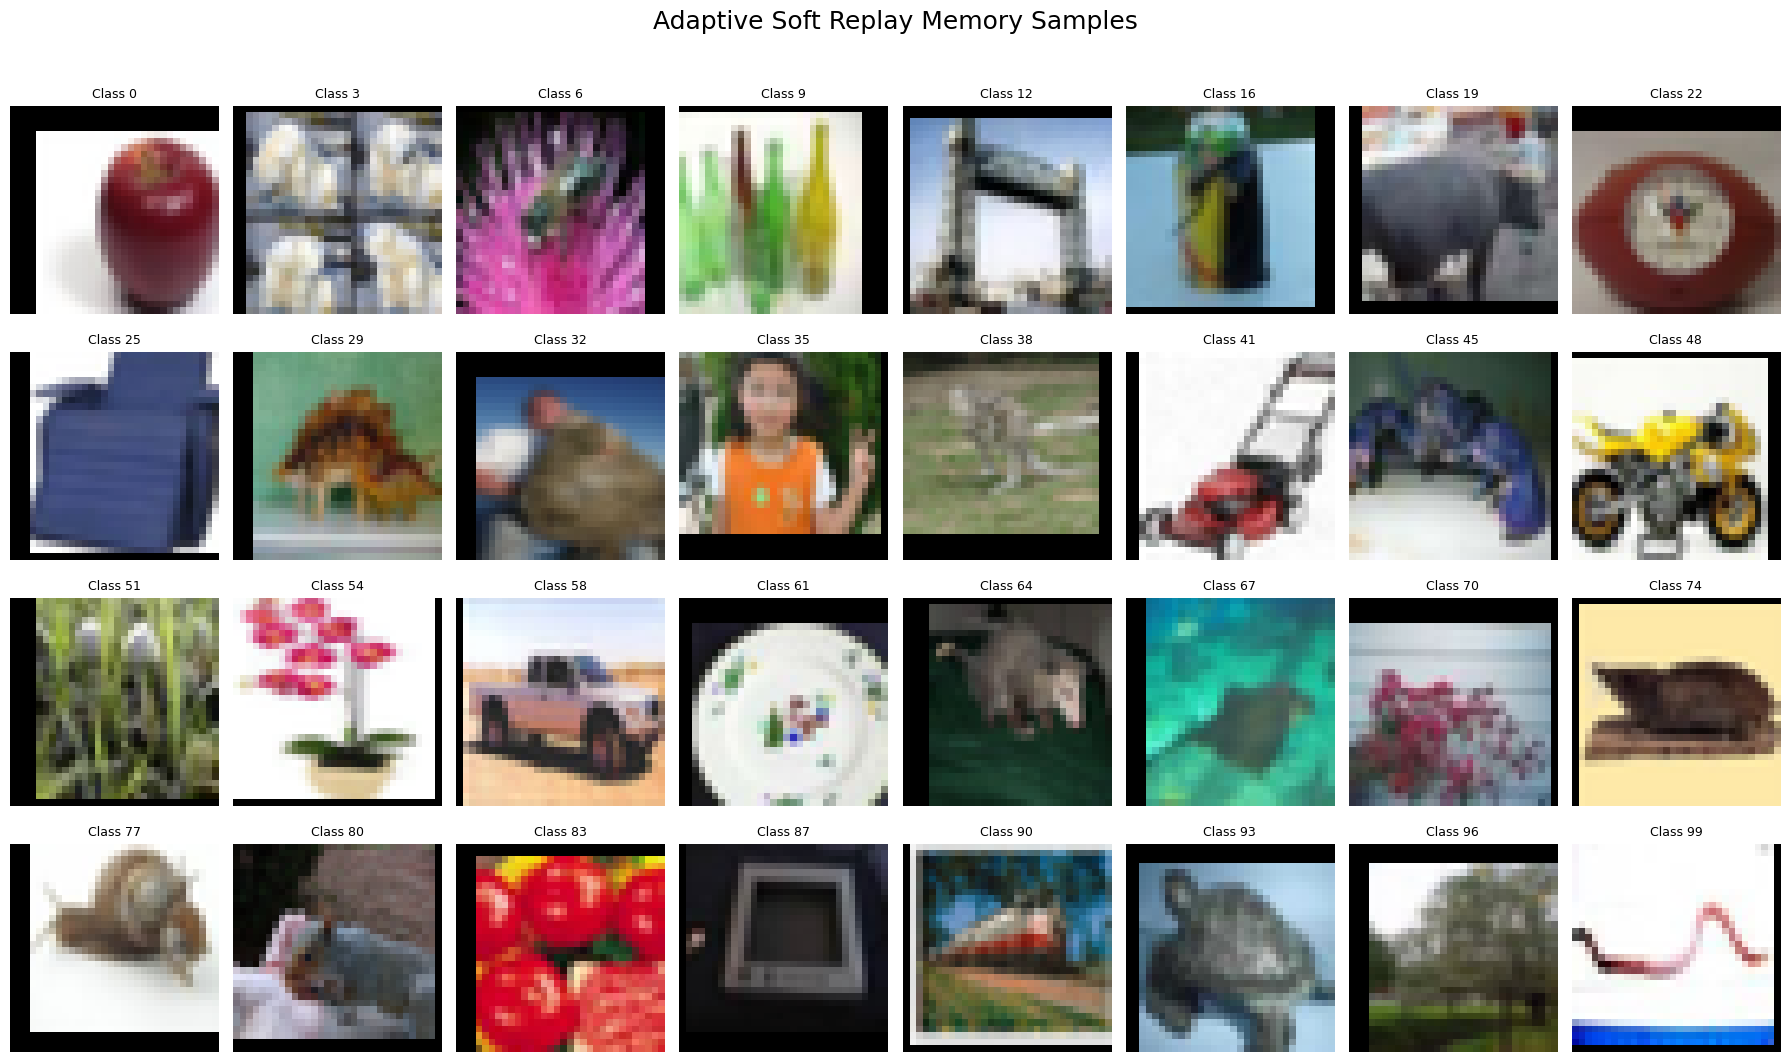

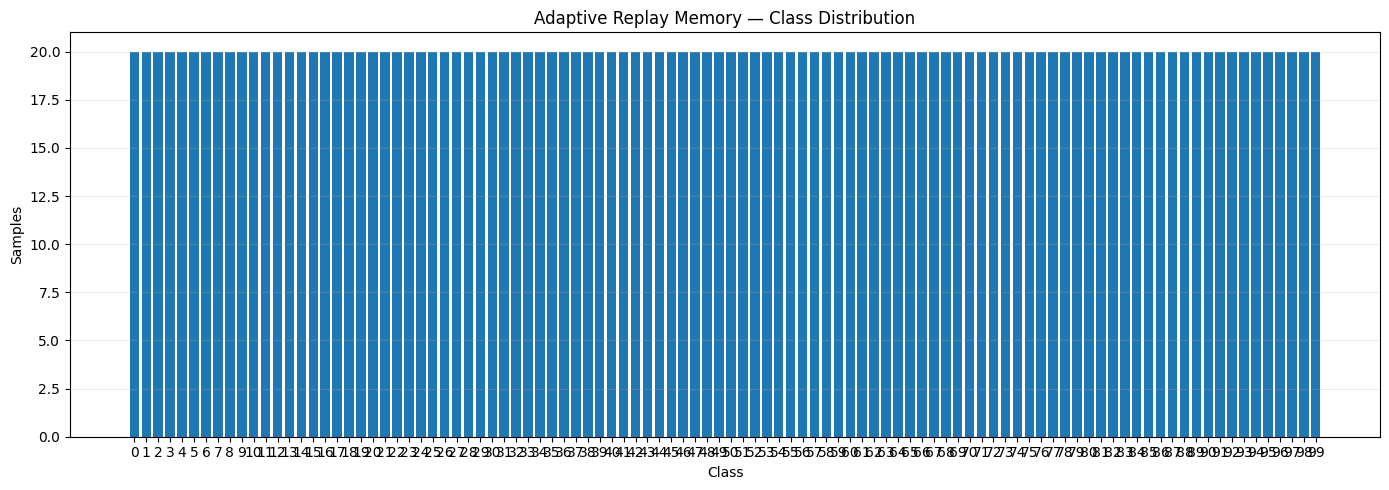

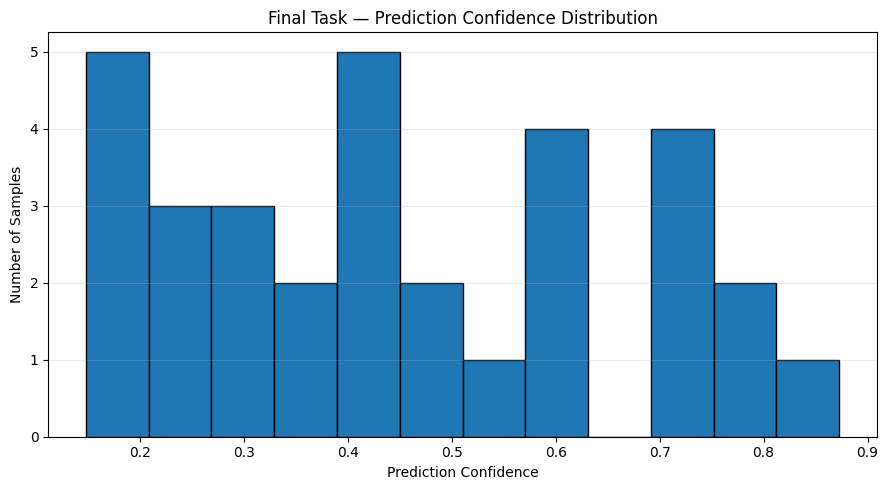

,Analysis,Samples / Status
0,Final Task Image Predictions,32
1,Incorrect Predictions,18
2,Replay Memory Samples,2000
3,Replay Memory Distribution,100 active classes
4,Prediction Confidence,32


In [ ]:


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F

from torch.utils.data import DataLoader, Subset

# ---------------------------------------------------------
# 1. Configuration
# ---------------------------------------------------------

model.eval()

FINAL_TASK = N_TASKS - 1
DISPLAY_SAMPLES = 32
BATCH_SIZE_VIS = 64
IMAGE_SIZE = 128

# ---------------------------------------------------------
# 2. Load final-task test samples
# ---------------------------------------------------------

test_rng = np.random.default_rng(SEED_RUN + 5000)

available_indices = np.arange(
    len(test_tasks[FINAL_TASK])
)

display_count = min(
    DISPLAY_SAMPLES,
    len(available_indices)
)

selected_indices = test_rng.choice(
    available_indices,
    size=display_count,
    replace=False
)

visual_loader = DataLoader(
    Subset(
        test_tasks[FINAL_TASK],
        selected_indices
    ),
    batch_size=BATCH_SIZE_VIS,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

# ---------------------------------------------------------
# 3. Generate predictions
# ---------------------------------------------------------

all_images = []
all_true = []
all_pred = []
all_confidence = []

with torch.no_grad():

    for x, y in visual_loader:

        x_device = x.to(
            device,
            non_blocking=True
        )

        logits = model(x_device)

        probabilities = F.softmax(
            logits,
            dim=1
        )

        confidence, prediction = probabilities.max(
            dim=1
        )

        all_images.append(
            x.cpu()
        )

        all_true.append(
            y.cpu()
        )

        all_pred.append(
            prediction.cpu()
        )

        all_confidence.append(
            confidence.cpu()
        )

images = torch.cat(all_images)[:DISPLAY_SAMPLES]
true_labels = torch.cat(all_true)[:DISPLAY_SAMPLES]
pred_labels = torch.cat(all_pred)[:DISPLAY_SAMPLES]
confidences = torch.cat(all_confidence)[:DISPLAY_SAMPLES]

# ---------------------------------------------------------
# 4. Denormalize images
# ---------------------------------------------------------

mean_tensor = torch.tensor(
    mean,
    dtype=torch.float32
).view(1, 3, 1, 1)

std_tensor = torch.tensor(
    std,
    dtype=torch.float32
).view(1, 3, 1, 1)

images = (
    images * std_tensor
    + mean_tensor
)

images = torch.clamp(
    images,
    0,
    1
)

# ---------------------------------------------------------
# 5. Nearest-neighbor enlargement
# ---------------------------------------------------------
# Original CIFAR-100 image = 32×32
# Display size = 128×128
# No smoothing/interpolation is introduced.

images_large = F.interpolate(
    images,
    size=(IMAGE_SIZE, IMAGE_SIZE),
    mode="nearest"
)

# ---------------------------------------------------------
# 6. Prediction status
# ---------------------------------------------------------

correct_mask = (
    true_labels == pred_labels
)

correct_count = int(
    correct_mask.sum()
)

incorrect_count = int(
    (~correct_mask).sum()
)

accuracy = (
    correct_count
    / len(true_labels)
    * 100
)

# ---------------------------------------------------------
# 7. Main prediction visualization
# ---------------------------------------------------------

fig, axes = plt.subplots(
    4,
    8,
    figsize=(18, 11)
)

for i, ax in enumerate(axes.flat):

    if i >= len(images_large):
        ax.axis("off")
        continue

    image = (
        images_large[i]
        .permute(1, 2, 0)
        .numpy()
    )

    ax.imshow(
        image,
        interpolation="nearest"
    )

    true_class = int(
        true_labels[i]
    )

    predicted_class = int(
        pred_labels[i]
    )

    confidence = float(
        confidences[i]
    )

    if true_class == predicted_class:

        title = (
            f"True: {true_class} | "
            f"Pred: {predicted_class}\n"
            f"Confidence: {confidence:.2f}"
        )

    else:

        title = (
            f"True: {true_class} | "
            f"Pred: {predicted_class}\n"
            f"Confidence: {confidence:.2f}"
        )

    ax.set_title(
        title,
        fontsize=8
    )

    ax.axis("off")

plt.suptitle(
    f"Final Task ({FINAL_TASK + 1}) — "
    f"CIFAR-100 Model Predictions",
    fontsize=18
)

plt.tight_layout(
    rect=[0, 0, 1, 0.96]
)

plt.show()

# ---------------------------------------------------------
# 8. Prediction summary
# ---------------------------------------------------------

prediction_summary = pd.DataFrame({

    "Metric": [
        "Displayed Samples",
        "Correct Predictions",
        "Incorrect Predictions",
        "Displayed Accuracy"
    ],

    "Value": [
        len(true_labels),
        correct_count,
        incorrect_count,
        f"{accuracy:.2f}%"
    ]
})

display(prediction_summary)

# ---------------------------------------------------------
# 9. Incorrect prediction visualization
# ---------------------------------------------------------

incorrect_indices = torch.where(
    ~correct_mask
)[0]

if len(incorrect_indices) > 0:

    incorrect_display = incorrect_indices[:24]

    rows = int(
        np.ceil(
            len(incorrect_display) / 6
        )
    )

    fig, axes = plt.subplots(
        rows,
        6,
        figsize=(15, 3.2 * rows)
    )

    axes = np.asarray(
        axes
    ).reshape(-1)

    for i, ax in enumerate(axes):

        if i >= len(incorrect_display):
            ax.axis("off")
            continue

        idx = incorrect_display[i]

        image = (
            images_large[idx]
            .permute(1, 2, 0)
            .numpy()
        )

        ax.imshow(
            image,
            interpolation="nearest"
        )

        ax.set_title(
            f"True: {int(true_labels[idx])}\n"
            f"Pred: {int(pred_labels[idx])} | "
            f"{float(confidences[idx]):.2f}",
            fontsize=9
        )

        ax.axis("off")

    plt.suptitle(
        "Incorrect Predictions — Final Task",
        fontsize=17
    )

    plt.tight_layout(
        rect=[0, 0, 1, 0.95]
    )

    plt.show()

else:

    display(
        pd.DataFrame({
            "Result": [
                "No incorrect predictions in displayed samples"
            ]
        })
    )

# ---------------------------------------------------------
# 10. Replay memory visualization
# ---------------------------------------------------------

if len(memory) > 0:

    memory_count = min(
        32,
        len(memory)
    )

    memory_indices = np.linspace(
        0,
        len(memory) - 1,
        memory_count,
        dtype=int
    )

    memory_images = []
    memory_labels = []

    for idx in memory_indices:

        image, label = memory[idx]

        memory_images.append(
            image
        )

        memory_labels.append(
            int(label)
        )

    memory_images = torch.stack(
        memory_images
    )

    memory_labels = np.asarray(
        memory_labels
    )

    memory_images = (
        memory_images
        * std_tensor
        + mean_tensor
    )

    memory_images = torch.clamp(
        memory_images,
        0,
        1
    )

    memory_images_large = F.interpolate(
        memory_images,
        size=(IMAGE_SIZE, IMAGE_SIZE),
        mode="nearest"
    )

    fig, axes = plt.subplots(
        4,
        8,
        figsize=(18, 11)
    )

    for i, ax in enumerate(
        axes.flat
    ):

        if i >= len(memory_images_large):
            ax.axis("off")
            continue

        image = (
            memory_images_large[i]
            .permute(1, 2, 0)
            .numpy()
        )

        ax.imshow(
            image,
            interpolation="nearest"
        )

        ax.set_title(
            f"Class {memory_labels[i]}",
            fontsize=9
        )

        ax.axis("off")

    plt.suptitle(
        "Adaptive Soft Replay Memory Samples",
        fontsize=18
    )

    plt.tight_layout(
        rect=[0, 0, 1, 0.96]
    )

    plt.show()

# ---------------------------------------------------------
# 11. Replay memory class distribution
# ---------------------------------------------------------

if len(memory) > 0:

    memory_class_counts = np.bincount(
        [
            int(label)
            for _, label in memory
        ],
        minlength=N_CLASSES
    )

    active_classes = np.where(
        memory_class_counts > 0
    )[0]

    plt.figure(
        figsize=(14, 5)
    )

    plt.bar(
        active_classes,
        memory_class_counts[
            active_classes
        ]
    )

    plt.xlabel(
        "Class"
    )

    plt.ylabel(
        "Samples"
    )

    plt.title(
        "Adaptive Replay Memory — Class Distribution"
    )

    plt.xticks(
        active_classes
    )

    plt.grid(
        axis="y",
        alpha=0.25
    )

    plt.tight_layout()
    plt.show()

# ---------------------------------------------------------
# 12. Prediction confidence
# ---------------------------------------------------------

plt.figure(
    figsize=(9, 5)
)

plt.hist(
    confidences.numpy(),
    bins=12,
    edgecolor="black"
)

plt.xlabel(
    "Prediction Confidence"
)

plt.ylabel(
    "Number of Samples"
)

plt.title(
    "Final Task — Prediction Confidence Distribution"
)

plt.grid(
    axis="y",
    alpha=0.25
)

plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 13. Final visual analysis summary
# ---------------------------------------------------------

visual_summary = pd.DataFrame({

    "Analysis": [
        "Final Task Image Predictions",
        "Incorrect Predictions",
        "Replay Memory Samples",
        "Replay Memory Distribution",
        "Prediction Confidence"
    ],

    "Samples / Status": [
        len(images),
        incorrect_count,
        len(memory),
        f"{np.count_nonzero(memory_class_counts)} active classes"
        if len(memory) > 0
        else "No memory",
        len(confidences)
    ]
})

display(visual_summary)